# Human influence in Rural Wildfires ignitions

## Group: 02
### Name(s) & ID(s) of Group Members:
- Benedita Barreto da Costa Gonçalves - 202205903
- Isabela Moreira Merelles - 202602764
- Maria Leonor Soares Carvalho - 202307522
- Mariana Vale de Oliveira Coelho de Pinho - 202306234

## Table of Contents

1. [Research Question](#1-research-question)
2. [Collect Data](#2-collect-data)
3. [Explore & Draw Inferences](#3-explore-and-draw-inferences)
4. [Formulate Conclusions](#4-formulate-conclusions)
5. [Look Back and Ahead](#5-look-back-and-ahead)

---

## 1) Research Question

How did initial response times and burnt areas change before and after 2017, and how are these two variables associated across four Portuguese municipalities?

### Secondary Research Questions:

1. Was the change in the proportion of negligent causes concentrated in the critical summer period, or did it also affect the traditional burning months (autumn/winter)?

    Difference in proportion (Variables to use: cause_type, period, season_risk_period). Test: Z test


2. Did the reduction in negligent wildfire occurrences translate into a significantly lower mean number of daily ignitions on weekends compared to weekdays?

    Mean comparison (Variables to use: Daily_Ignitions_Count, Day_Type, Period). Test: t-test


3. Do final burnt areas differ significantly across the four municipalities under study?

    ANOVA (Variables: Log_Total_Burnt_Area, Municipality). Test: One-way ANOVA.


4. Did the disparity in final burnt area between intentional and negligent causes narrow in the post-2017 period in the municipalities under study?

    ANOVA (Variables to use: Log_Total_Burnt_Area, Cause_Type_Period). Test: Two-way ANOVA 


---

## 2) Collect data

### Dataset Source

The dataset used in this project was sourced from the Institute for Nature Conservation and Forests (ICNF), specifically the wildfire statistics published under the Information Management section of [their website](https://www.icnf.pt/florestas/gfr/gfrgestaoinformacao/estatisticas). This dataset contains data on human influenced wildfire ignitions from 2001 until 2025. The records are split across three ICNF files (2001-2010, 2011-2020 and 2021-2025), and were combined into a single dataset before analysis.

The raw file contains 40 columns covering fire identifiers, location, timestamps, burnt area by land cover, fire weather indices, and cause classification. Only a subset of these columns was used in the analysis, and several variables were derived from them. The full mapping is described below so that the variables can be reproduced from the raw file.

### Dataset Details


#### Variables: 

##### Qualitative Variables

- **Cause_Type**: Intentional vs. Negligent. Derived from the cause classification columns (`TipoCausa`, `GrupoCausa`, `CodCausa`), keeping only validated human causes. Fires with an unclassified or unknown cause were excluded.

- **Period**: Pre-2017 (2001–2016) vs. Post-2017 (2018–2025). Derived from `Ano`. In practice, the law was only implemented in 2021, so the post-2017 group mixes pre-law and post-law years (see limitations).

- **Municipality**: Chaves, Montalegre, Ourém, Tomar. Taken from `Concelho`.

- **Season_Risk_Period**: Critical Period vs. Non-Critical Period. Derived from `Mes` and `Dia`, with the critical period defined as 1 June to 30 September.

- **Day_Type**: Weekend vs. Weekday. Derived from the fire date (`Ano`, `Mes`, `Dia`), with Saturday and Sunday classified as weekend.

- **Cause_Type_Period**: Combined factor of `Cause_Type` and `Period`, used for the two-way ANOVA in Q4.

##### Quantitative Variables

- **Daily_Ignitions_Count**: Number of ignitions per municipality per day, computed by counting `Codigo_SGIF` grouped by `date` and `municipality`.

- **Total_Burnt_Area**: Total surface burnt per occurrence, in hectares, from `AreaTotal_ha`.

- **Initial_Response_Time**: Time in minutes between `DataHoraAlerta` and `DataHora_PrimeiraIntervencao`.

- **Fire_Duration**: Total duration from fire alert to final extinction, in hours, from `Duracao_Horas`.

### Data preparation

In [23]:
import numpy as np
import pandas as pd
from pathlib import Path

project_path = Path.cwd()
raw = project_path / "01_dataset/raw"
processed = project_path / "01_dataset/processed"
processed.mkdir(parents=True, exist_ok=True)

In [13]:
#Loading the data
cols_necessarias = [
    'Ano', 'Mes', 'Dia', 'Hora', 'AreaTotal_ha', 'Duracao_Horas',
    'DataHoraAlerta', 'DataHora_PrimeiraIntervencao', 'DataHora_Extincao',
    'Concelho', 'TipoCausa', 'Codigo_SGIF'
]

df1 = pd.read_excel(raw / "Registos_Incendios_SGIF_2021_2025.xlsx", usecols=cols_necessarias)
df2 = pd.read_excel(raw / "Registos_Incendios_SGIF_2011_2020.xlsx", usecols=cols_necessarias)
df3 = pd.read_excel(raw / "Registos_Incendios_SGIF_2001_2010.xlsx", usecols=cols_necessarias)

# confirm the raw files share the same schema
print("df1 vs df2:", df1.columns.equals(df2.columns))
print("df2 vs df3:", df2.columns.equals(df3.columns))

/var/folders/n2/bvvvs5j937xbw0hlvdr0s4c80000gn/T/ipykernel_94637/1537968763.py:10: FutureWarning: Inferring datetime64[ns] from data containing strings is deprecated and will be removed in a future version. To retain the old behavior explicitly pass Series(data, dtype=datetime64[ns])
  df3 = pd.read_excel(raw / "Registos_Incendios_SGIF_2001_2010.xlsx", usecols=cols_necessarias)


df1 vs df2: True
df2 vs df3: True


Before deriving variables, the sample size was checked by municipality and year to confirm that all four municipalities are represented across the full period.

In [14]:
# Concatenar os 3 ficheiros (2001 a 2025)
df = pd.concat([df1, df2, df3], ignore_index=True)

concelhos = ["Chaves", "Ourém", "Montalegre", "Tomar"]

# Filtrar pelos 4 concelhos e pela janela completa de 2001 a 2025
df_final = df[df["Concelho"].isin(concelhos)].copy()
df_final = df_final[df_final["Ano"].between(2001, 2025)].copy()

print(df_final["Concelho"].value_counts())
print(pd.crosstab(df_final["Concelho"], df_final["Ano"], margins=True))

Montalegre    5635
Chaves        3914
Ourém         2691
Tomar         2280
Name: Concelho, dtype: int64
Ano         2001  2002  2003  2004  2005  2006  2007  2008  2009  2010  ...  \
Concelho                                                                ...   
Chaves       259   307   127   188   326   167   130   139   308   127  ...   
Montalegre   262   283   177   194   390   147   238   149   475   177  ...   
Ourém        118   159   116   166   293   188   136   144    99    97  ...   
Tomar         58   115    86   166   186   125   130   108   110    95  ...   
All          697   864   506   714  1195   627   634   540   992   496  ...   

Ano         2017  2018  2019  2020  2021  2022  2023  2024  2025    All  
Concelho                                                                 
Chaves       132    67    66    73    46   105    36    68    94   3914  
Montalegre   314   119   168   134   191   192   117    94   131   5635  
Ourém         96    82    63    97    64    8

In [15]:
# quantitative variables:

#Initial_Response_Time
for col in ["DataHoraAlerta", "DataHora_PrimeiraIntervencao", "DataHora_Extincao"]:
  df_final[col] = pd.to_datetime(df_final[col], errors="coerce")

df_final["Initial_Response_Time"] = (
    df_final["DataHora_PrimeiraIntervencao"] - df_final["DataHoraAlerta"]
).dt.total_seconds() / 60

#Fire_Duration
df_final["Fire_Duration"] = df_final["Duracao_Horas"]

#Total_Burnt_Area
df_final["Total_Burnt_Area"] = df_final["AreaTotal_ha"]

# Escala logarítmica para cumprir os pressupostos das ANOVAs
df_final["Log_Total_Burnt_Area"] = np.log10(df_final["Total_Burnt_Area"] + 0.001)

In [16]:
#qualitative variables:

#Period
df_final["Period"] = np.where(df_final["Ano"] <= 2016, "Pre-2017",
                       np.where(df_final["Ano"] >= 2018, "Post-2017", "Transition"))

#Season_Risk_Period
df_final["Season_Risk_Period"] = np.where(
    df_final["Mes"].isin([6, 7, 8, 9]),
    "Critical", "Non-Critical"
)

#Day_Type
df_final["Day_Type"] = np.where(
    df_final["DataHoraAlerta"].dt.dayofweek >= 5,
    "Weekend", "Weekday"
)

In [17]:
# 1. Mapear apenas causas humanas apuradas
cause_map = {
    "Negligente": "Negligent",
    "Intencional": "Intentional",
}

df_final["Cause_Type"] = df_final["TipoCausa"].map(cause_map)

df_final["Cause_Type_Period"] = np.where(
    df_final["Cause_Type"].isna(),
    np.nan,
    df_final["Cause_Type"].astype(str) + "_" + df_final["Period"].astype(str),
)

# 2. Contagem diária de ignições negligentes (excluindo 2017) para a Q2
df_final["Date"] = df_final["DataHoraAlerta"].dt.date

df_neg = df_final[
    (df_final["Cause_Type"] == "Negligent")
    & (df_final["Period"] != "Transition")
].copy()

daily = (
    df_neg.groupby(["Concelho", "Date", "Period"])
    .size()
    .reset_index(name="Daily_Ignitions_Count")
)

daily["Day_Type"] = np.where(
    pd.to_datetime(daily["Date"]).dt.dayofweek >= 5, "Weekend", "Weekday"
)

In [18]:
# Count missing values in each column
print(f"\nNumber of missing values for each column/ feature:")
print(df_final.isnull().sum())


Number of missing values for each column/ feature:
Codigo_SGIF                        0
Ano                                0
Mes                                0
Dia                                0
Hora                               0
AreaTotal_ha                       0
DataHoraAlerta                     0
DataHora_PrimeiraIntervencao    5583
DataHora_Extincao                 43
Duracao_Horas                     43
Concelho                           0
TipoCausa                       6043
Initial_Response_Time           5583
Fire_Duration                     43
Total_Burnt_Area                   0
Log_Total_Burnt_Area               0
Period                             0
Season_Risk_Period                 0
Day_Type                           0
Cause_Type                      7357
Cause_Type_Period               7357
Date                               0
dtype: int64


In [19]:
df_final.describe()

,Ano,Mes,Dia,Hora,AreaTotal_ha,Duracao_Horas,Initial_Response_Time,Fire_Duration,Total_Burnt_Area,Log_Total_Burnt_Area
count,14520.000000,14520.000000,14520.000000,14520.000000,14520.000000,14477.000000,8937.000000,14477.000000,14520.000000,14520.000000
mean,2011.001446,6.891116,15.793595,14.687190,9.087475,2.433111,18.117153,2.433111,9.087475,-0.772434
std,6.668413,2.635995,8.666318,5.363572,116.325010,6.112195,30.905899,6.112195,116.325010,1.203978
min,2001.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-3.000000
25%,2005.000000,5.000000,8.000000,12.000000,0.010000,0.616667,9.000000,0.616667,0.010000,-1.958607
50%,2010.000000,8.000000,16.000000,15.000000,0.200000,1.250000,14.000000,1.250000,0.200000,-0.696804
75%,2016.000000,9.000000,23.000000,18.000000,1.130000,2.533333,20.000000,2.533333,1.130000,0.053463
max,2025.000000,12.000000,31.000000,23.000000,6379.000000,244.550000,1456.000000,244.550000,6379.000000,3.804753


Saving processed data to be used for statistics

In [20]:
df_final.to_excel(processed / "wildfires_processed.xlsx", index=False)
daily.to_excel(processed / "daily_ignitions.xlsx", index=False)

Per question dataset

In [21]:
# Q1: Negligente vs Intencional, Pré vs Pós, Crítico vs Não-Crítico (Z-test)
q1 = df_final[
    (df_final["Cause_Type"].notna()) & (df_final["Period"] != "Transition")
].copy()
q1.to_excel(processed / "q1_cause_period_season.xlsx", index=False)

# Q2: Ignições diárias de causas negligentes, Weekend vs Weekday (t-test)
q2 = daily.dropna(subset=["Date", "Daily_Ignitions_Count"]).copy()
q2.to_excel(processed / "q2_daily_ignitions.xlsx", index=False)

# Q3: Área ardida por Concelho (One-way ANOVA)
q3 = df_final[
    (df_final["Total_Burnt_Area"].notna())
    & (df_final["Period"] != "Transition")
].copy()
q3.to_excel(processed / "q3_burnt_area_municipality.xlsx", index=False)

# Q4: Área ardida por Cause_Type e Period (Two-way ANOVA)
q4 = df_final[
    (df_final["Cause_Type"].notna())
    & (df_final["Period"] != "Transition")
    & (df_final["Total_Burnt_Area"].notna())
].copy()
q4.to_excel(processed / "q4_burnt_area_cause_period.xlsx", index=False)

#### Missing values

| Question | Variables used | rows dropped where |
|---|---|---|
| Q1 | `Cause_Type`, `Period`, `Season_Risk_Period` | `Cause_Type` is missing or `Period == 'Transition'` (2017) |
| Q2 | `Daily_Ignitions_Count`, `Day_Type`, `Period` | Non-negligent causes, date is missing, or `Period == 'Transition'` |
| Q3 | `Log_Total_Burnt_Area`, `Municipality` | `Total_Burnt_Area` is missing or `Period == 'Transition'` |
| Q4 | `Log_Total_Burnt_Area`, `Cause_Type`, `Period` | `Cause_Type` or `Total_Burnt_Area` is missing, or `Period == 'Transition'` |

In [22]:
log = pd.DataFrame({
    "dataset": ["pooled", "q1", "q2", "q3", "q4"],
    "n_rows": [len(df_final), len(q1), len(q2), len(q3), len(q4)],
    "exclusion": [
        "Initial 4-municipality cohort (2001-2025)",
        "Missing Cause_Type and Transition year (2017) excluded",
        "Negligent daily counts (2017 excluded)",
        "Missing Burnt Area and 2017 excluded",
        "Missing Cause_Type, Burnt Area, and 2017 excluded",
    ],
})
log.to_excel(processed / "sample_sizes.xlsx", index=False)
log

,dataset,n_rows,exclusion
0,pooled,14520,Initial 4-municipality cohort (2001-2025)
1,q1,6519,Missing Cause_Type and Transition year (2017) ...
2,q2,2897,Negligent daily counts (2017 excluded)
3,q3,13816,Missing Burnt Area and 2017 excluded
4,q4,6519,"Missing Cause_Type, Burnt Area, and 2017 excluded"


---

## 3) Explore and draw inferences

### Changes in Negligent Causes (Q1)

In this first phase, we focused on Q1: testing whether the change in the proportion of negligent causes was concentrated in the critical summer period or if it also affected autumn and winter burning months.

### Checking count of data

In [30]:
q1_counts = pd.crosstab(
    [q1["Period"], q1["Season_Risk_Period"]],
    q1["Cause_Type"],
    margins=True
)
q1_counts

Cause_Type                    Intentional  Negligent   All
Period    Season_Risk_Period                              
Post-2017 Critical                    639        576  1215
          Non-Critical                150       1120  1270
Pre-2017  Critical                   1120       1411  2531
          Non-Critical                261       1242  1503
All                                  2170       4349  6519

The total sample for Q1 consists of 6,519 fires due to human cause.

All four combinations have more than 1,200 observations. This means the sample is large enough to trust the Z-test on proportions, and we do not need to worry about small-cell bias.

In the critical period, the counts show intentional fires dropped (from 1,120 to 639), but negligent fires dropped evenmore (from 1,411 to 576).

#### Checking proportion of dataset

In [29]:
q1_props = (
    q1.groupby(["Period", "Season_Risk_Period"])["Cause_Type"]
      .apply(lambda s: (s == "Negligent").mean())
      .reset_index(name="negligent_share")
)
q1_props

,Period,Season_Risk_Period,negligent_share
0,Post-2017,Critical,0.474074
1,Post-2017,Non-Critical,0.881890
2,Pre-2017,Critical,0.557487
3,Pre-2017,Non-Critical,0.826347


In the Critical period, negligent ignitions dropped from 55.7% to 47.4% post-2017. 

In the Non-Critical period, the negligent share actually went up from 82.6% to 88.2%. This is because the counts show that intentional fires in this season fell (261 down to 150), while negligent fires stayed relatively stable (1,242 down to 1,120). Because intentional fires dropped faster than negligent ones, the overall proportion of negligent fires went up.

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
%config InlineBackend.figure_format = "retina"
plt.style.use("seaborn-v0_8")

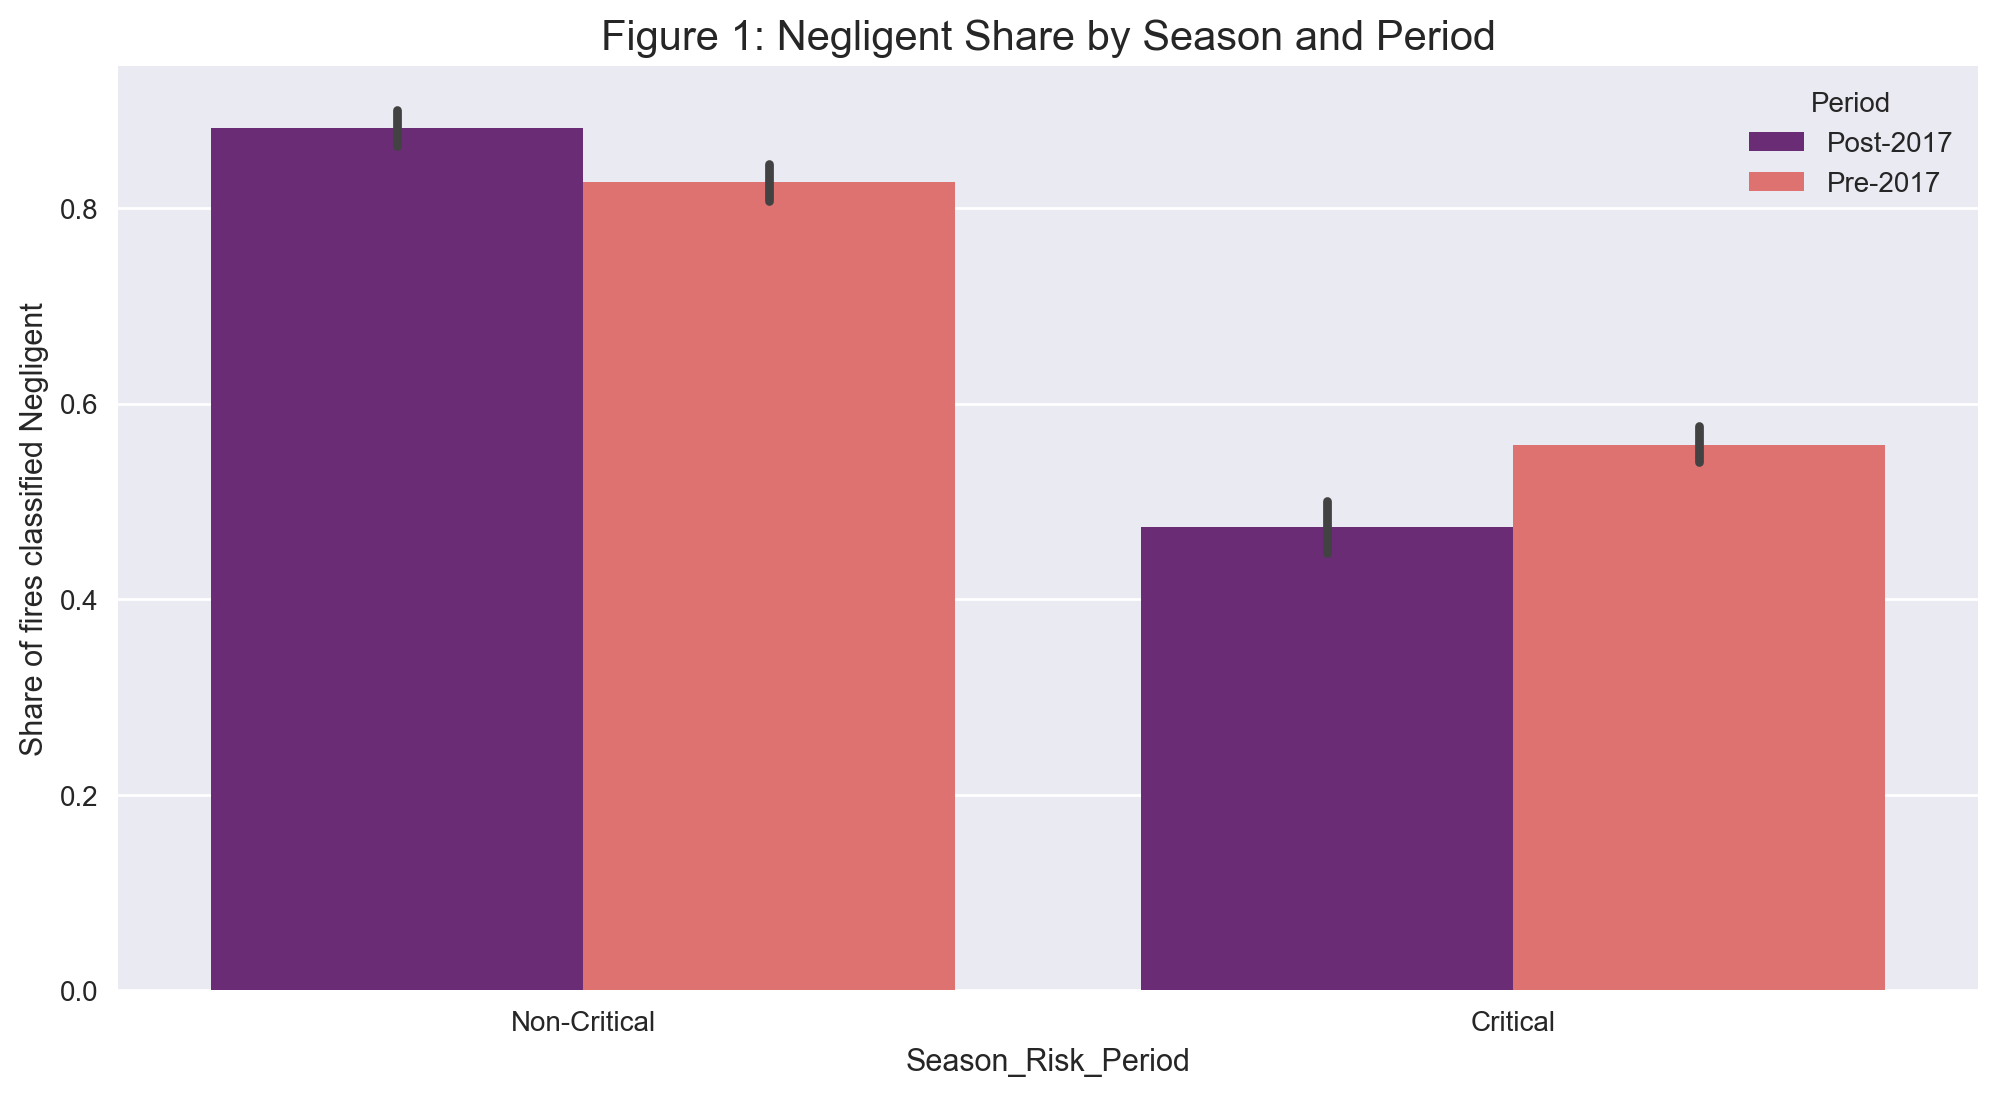

In [34]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=q1, x="Season_Risk_Period", y=(q1["Cause_Type"] == "Negligent").astype(int),
    hue="Period", palette="magma", errorbar="ci"
)
plt.title("Figure 1: Negligent Share by Season and Period", fontsize=15)
plt.ylabel("Share of fires classified Negligent")
plt.show()

Figure 1 shows the change in the proportion of negligent fires between the pre-2017 and post-2017 periods, split by season. 

The decline in fires seem to happen mainly in the **Critical** period. The error bars do not overlap, meaning this drop is likely statistically significant.

In the **Non-Critical** period, the share remains very high in both periods. The slight increase is small and the error bars overlap, suggesting there is no real change.

#### Checking negligence over time

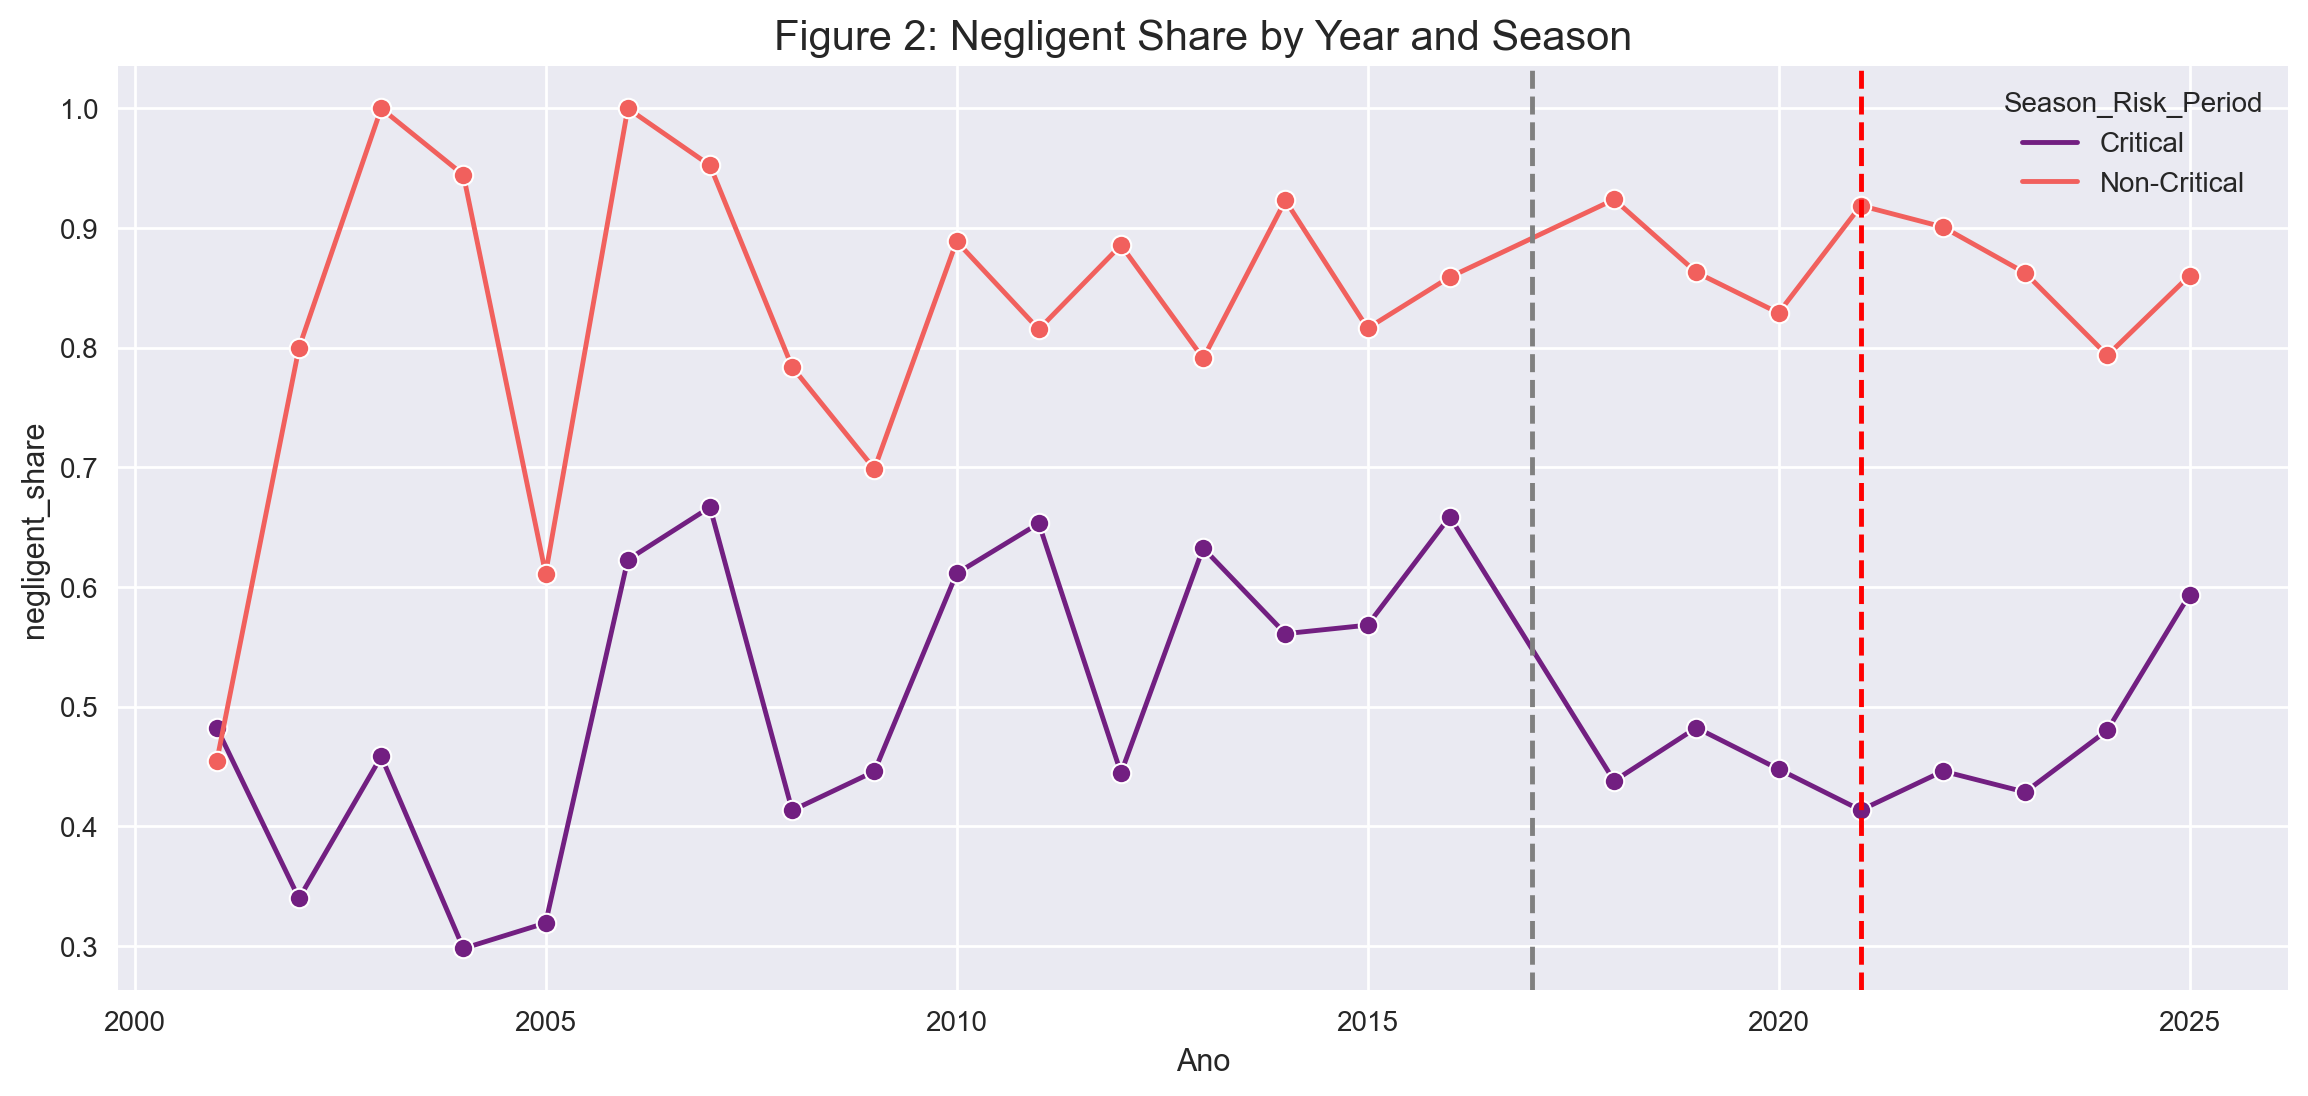

In [35]:
year_season = (
    q1.groupby(["Ano", "Season_Risk_Period"])["Cause_Type"]
      .apply(lambda s: (s == "Negligent").mean())
      .reset_index(name="negligent_share")
)

plt.figure(figsize=(14, 6))
sns.lineplot(data=year_season, x="Ano", y="negligent_share",
             hue="Season_Risk_Period", marker="o", palette="magma")
plt.axvline(2017, color="grey", linestyle="--")
plt.axvline(2021, color="red", linestyle="--")
plt.title("Figure 2: Negligent Share by Year and Season", fontsize=15)
plt.show()

#### Conclusions

To explore this question, we split the data into pre-2017 and post-2017 periods and compared the negligent share between critical and non-critical seasons. The visualisations and proportions showed a clear divergence between the seasons. In the critical period, the negligent share dropped from 55.7% to 47.4% after 2017. But, in the non-critical months, the share of negligent fires actually increased from 82.6% to 88.2%.

This means that the seasons do not behave in the same way, the reduction in negligent ignitions did not affect the whole year. It was entirely concentrated in the critical summer months.

Also, if the law implemented in 2021 actually deterred negligent ignitions, we would expect a sharp drop right after the red line in Figure 2. Instead, the non-critical line stays flat, and the critical line drops slightly in 2021 but climbs right back up by 2024/2025.

## 5) Look back and ahead

### Limitations of the Dataset

Two limitations affect interpretation and should be kept in mind when reading the results.

First, the Period split is set at 2017, but the law was only implemented in 2021. The post-2017 group therefore mixes years before and after the law took effect, so any change attributed to the post-2017 period cannot be separated from the effect of the law itself without a further split.

Second, Initial_Response_Time and Fire_Duration depend on how consistently timestamps are recorded across municipalities. The alert source (FonteAlerta) also varies, and response time depends partly on who reported the fire. These differences may introduce variation between municipalities that is not caused by fire behaviour, which is relevant to the municipality comparison in Q4.